# Wednesday tutorial · From drillholes to a risk-aware mine plan
**MIME 525 · Simulation-Based Optimization and Reinforcement Learning**

Each group gets its **own deposit**: a different set of 30 drillholes (set `GROUP` below). With it you will
1. simulate many equally likely grade models with **SGS**, using all your CPU cores (**concurrency**),
2. turn each model into cash with the toy **DRS** mine simulator (**NPV**),
3. **optimize** the cutoff policy with **Bayesian optimization** (Optuna),
4. measure the **regret** of your decisions and the **risk** of your plan,
5. *(extensions)* choose a policy with a **bandit**, and beat the rule of thumb in the **repair-crew MDP**.

Tasks are numbered like the tutorial slides (A1, B1, …). Run the cells from top to bottom (Shift + Enter).
At the end, one cell prints your **group summary**: copy it into the class table.

**Before you start:** put `sgs_tools.py` next to this notebook (on Colab, the next cell asks you to upload it).

> Free Colab has 2 *virtual* CPUs, so parallel speed-ups there are small (about 1.5–1.9×). A laptop usually shows bigger ones.

---
## Task 0 · Setup: your group and your deposit

In [1]:
# Colab only: install Optuna and upload sgs_tools.py if needed. On a laptop: pip install optuna
import os
import warnings
warnings.filterwarnings("ignore")
try:
    import optuna
except ImportError:
    os.system("pip install -q optuna")
if not os.path.exists("sgs_tools.py"):
    from google.colab import files
    files.upload()

In [2]:
import time
import threading
import functools
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor, as_completed
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import sgs_tools

GROUP = 0                       # <-- YOUR GROUP NUMBER (1, 2, 3, ...). 0 = the lecture deposit (instructor demo)
HOLES_SEED = 2026 + GROUP       # picks your deposit: a different "true" orebody and different drillholes

TRAIN = range(0, 30)            # 30 realizations to make decisions with
TEST = range(1000, 1100)        # 100 new realizations to check them on (never used to decide)
summary = {"group": GROUP}      # filled in as you go, printed at the end

print("Group", GROUP, "| deposit seed", HOLES_SEED, "| CPU cores:", os.cpu_count())

Group 0 | deposit seed 2026 | CPU cores: 2


# Part A · Concurrency warm-up (10 min)
The four exercises from the lecture. Write down each time.

---
## Task A1 · Sequential baseline: two counters, in order

In [3]:
n = 20_000_000

def count(n):
    total = 0
    for _ in range(n):
        total += 1
    return total

t0 = time.perf_counter()
a = count(n)
b = count(n)
time_A1 = time.perf_counter() - t0
print(a + b, round(time_A1, 2), "s")

40000000 1.23 s


---
## Task A2 · The lost update problem
Two **threads** share one total. **Predict before you run**: will it print 2 000 000?

In [4]:
n = 1_000_000
total = 0

def count_shared(n):
    global total
    for _ in range(n):
        total = (lambda x: x + 1)(total)     # read -> add one -> write, with a function call in between

threads = [threading.Thread(target=count_shared, args=(n,)) for _ in range(2)]
t0 = time.perf_counter()
for t in threads: t.start()
for t in threads: t.join()
print(total, round(time.perf_counter() - t0, 2), "s")

1358638 0.22 s


---
## Task A3 · Using locks

In [5]:
n = 1_000_000
total = 0
lock = threading.Lock()

def count_locked(n):
    global total
    for _ in range(n):
        with lock:                           # only one thread at a time
            total = (lambda x: x + 1)(total)

threads = [threading.Thread(target=count_locked, args=(n,)) for _ in range(2)]
t0 = time.perf_counter()
for t in threads: t.start()
for t in threads: t.join()
print(total, round(time.perf_counter() - t0, 2), "s")

2000000 0.46 s


---
## Task A4 · Parallelism with processes
Same work as A1, on two processes. In a notebook the function must come from a `.py` file: `sgs_tools.count`.

In [6]:
n = 20_000_000
t0 = time.perf_counter()
with ProcessPoolExecutor(2) as pool:
    a, b = pool.map(sgs_tools.count, [n, n])
time_A4 = time.perf_counter() - t0
print(a + b, round(time_A4, 2), "s   speed-up vs A1:", round(time_A1 / time_A4, 2), "x")

40000000 0.78 s   speed-up vs A1: 1.58 x


# Part B · Your deposit (15 min)

---
## Task B1 · Drill your deposit
Your 30 drillholes. Colour = Cu grade. Compare with the lecture deposit (GROUP = 0).

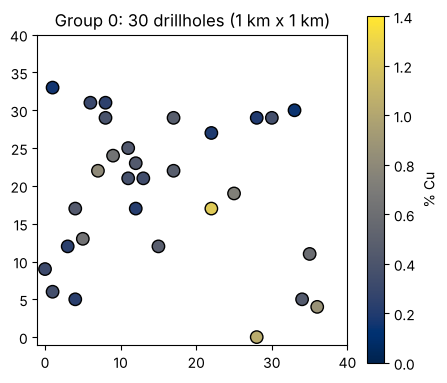

Mean drillhole grade: 0.459 % Cu   (lecture deposit: 0.459)
Holes at or above 0.5 % Cu: 8 of 30


In [7]:
holes, scores = sgs_tools.drillholes(HOLES_SEED)
hole_grades = sgs_tools.to_grade(scores)
hx, hy = [h[0] for h in holes], [h[1] for h in holes]

plt.figure(figsize=(5, 4.5))
plt.scatter(hx, hy, c=hole_grades, cmap="cividis", vmin=0, vmax=1.4, s=80, edgecolors="black")
plt.colorbar(label="% Cu")
plt.xlim(-1, 40); plt.ylim(-1, 40); plt.gca().set_aspect("equal")
plt.title(f"Group {GROUP}: 30 drillholes (1 km x 1 km)")
plt.show()

summary["holes_mean_grade"] = round(float(np.mean(hole_grades)), 3)
print("Mean drillhole grade:", summary["holes_mean_grade"], "% Cu   (lecture deposit: 0.459)")
print("Holes at or above 0.5 % Cu:", int(np.sum(hole_grades >= 0.5)), "of 30")

---
## Task B2 · One realization
One SGS run visits all 1 600 blocks in random order; each block is kriged from up to 12 known neighbours, then drawn at random.

In [8]:
t0 = time.perf_counter()
grade = sgs_tools.sgs_2d(0, HOLES_SEED)
time_one = time.perf_counter() - t0
print(f"One realization: {time_one:.2f} s,  mean grade {grade.mean():.3f} % Cu,  "
      f"ore (≥ 0.5 %) {(grade >= 0.5).sum() * sgs_tools.BLOCK_TONNES / 1e6:.1f} Mt")

One realization: 0.10 s,  mean grade 0.454 % Cu,  ore (≥ 0.5 %) 12.3 Mt


---
## Task B3 · Many realizations: one core vs all cores
Realizations are independent (each needs only its seed), so we send them to different cores. `functools.partial` fixes your deposit seed so `pool.map` only has to pass the realization seed.

In [9]:
simulate = functools.partial(sgs_tools.sgs_2d, holes_seed=HOLES_SEED)     # simulate(seed) -> grade map

t0 = time.perf_counter()
one_core = [simulate(s) for s in range(20)]
t_one = time.perf_counter() - t0

t0 = time.perf_counter()
with ProcessPoolExecutor() as pool:
    all_cores = list(pool.map(simulate, range(20)))
t_all = time.perf_counter() - t0

speedup = t_one / t_all
n_cores = os.cpu_count()
p = (1 - 1 / speedup) / (1 - 1 / n_cores) if n_cores > 1 else 1.0      # Amdahl's law, solved for p
print(f"20 realizations: 1 core {t_one:.1f} s -> {n_cores} cores {t_all:.1f} s  ({speedup:.2f}x)")
print("Same models:", all(np.array_equal(a, b) for a, b in zip(one_core, all_cores)))
print(f"Amdahl: this speed-up means about {min(p, 1):.0%} of the run is parallel")

# the realizations used for the rest of the tutorial, all in parallel
t0 = time.perf_counter()
with ProcessPoolExecutor() as pool:
    train = list(pool.map(simulate, TRAIN))
    test = list(pool.map(simulate, TEST))
print(f"{len(train)} training + {len(test)} test realizations in {time.perf_counter() - t0:.1f} s")
summary["speedup"] = round(speedup, 2)

20 realizations: 1 core 2.1 s -> 2 cores 1.2 s  (1.71x)
Same models: True
Amdahl: this speed-up means about 83% of the run is parallel


30 training + 100 test realizations in 7.0 s


---
## Task B4 · Maps: realizations, E-type and risk

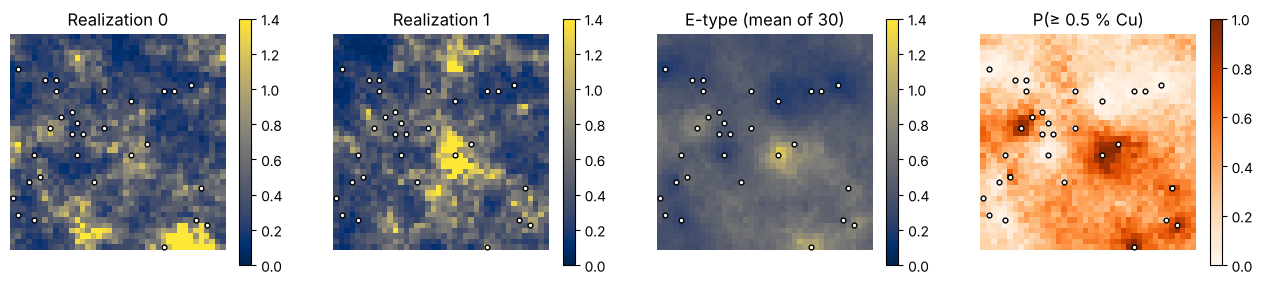

Ore ≥ 0.5 % Cu (Mt), P10 / P50 / P90 over 100 test realizations: [11.1, 13.4, 17.9]


In [10]:
etype = np.mean(train, axis=0)                     # block-by-block average of the 30 training models
p_ore = np.mean(np.array(train) >= 0.5, axis=0)    # chance each block is ore

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
pictures = [train[0], train[1], etype, p_ore]
titles = ["Realization 0", "Realization 1", "E-type (mean of 30)", "P(≥ 0.5 % Cu)"]
for i in range(4):
    img = ax[i].imshow(pictures[i].T, origin="lower", cmap="cividis" if i < 3 else "Oranges",
                       vmin=0, vmax=1.4 if i < 3 else 1)
    ax[i].scatter(hx, hy, s=12, c="white", edgecolors="black")
    ax[i].set_title(titles[i]); ax[i].axis("off")
    plt.colorbar(img, ax=ax[i], shrink=0.8)
plt.show()

ore = [(g >= 0.5).sum() * sgs_tools.BLOCK_TONNES / 1e6 for g in test]
summary["ore_P10_P50_P90_Mt"] = [round(float(x), 1) for x in np.percentile(ore, [10, 50, 90])]
print("Ore ≥ 0.5 % Cu (Mt), P10 / P50 / P90 over 100 test realizations:", summary["ore_P10_P50_P90_Mt"])

---
## Task B5 · How many realizations do you need?
Ask for up to 200, use each result **as soon as it finishes**, stop once the mean contained Cu is known within ±3 kt (standard error).

In [11]:
cu, order = [], []
with ProcessPoolExecutor() as pool:
    jobs = [pool.submit(sgs_tools.ore_summary, s, 0.5, HOLES_SEED) for s in range(200)]
    for job in as_completed(jobs):                        # in the order they FINISH
        cu.append(job.result()["cu_kt"])
        order.append(job.result()["seed"])
        error = np.std(cu) / np.sqrt(len(cu))             # uncertainty of the average
        if len(cu) >= 10 and error < 3:
            for j in jobs:
                j.cancel()                                # drop the jobs not started yet
            break
summary["realizations_needed"] = len(cu)
print("Needed", len(cu), "of 200 realizations.  Mean contained Cu:", round(np.mean(cu), 1), "±", round(2 * error, 1), "kt (95 %)")
print("Finish order:", order[:10])

Needed 49 of 200 realizations.  Mean contained Cu: 109.0 ± 5.9 kt (95 %)
Finish order: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


# Part C · From grades to cash (10 min)

---
## Task C1 · One DRS week by hand
Week 1 of realization 0 of your deposit, with the planner's first guess: cutoff 0.42 %, stockpile cutoff 0.32 %. Fill in the table on the slide, then check.

In [12]:
grade = train[0]
cutoff, stockpile_cutoff = 0.42, 0.32
mined = list(grade.ravel()[:8])                                    # first 8 blocks in mining order
rng = np.random.default_rng(0)
availability = np.clip(rng.normal(1.0, 0.15), 0.4, 1.2)
room = round(sgs_tools.PLANT_SIZE * availability)

to_plant = [g for g in mined if g >= cutoff]
stockpile = sorted(g for g in mined if stockpile_cutoff <= g < cutoff)
extra = to_plant[room:]                                            # plant full: wait on the stockpile
to_plant = to_plant[:room]
stockpile = sorted(stockpile + extra)
from_stockpile = []
while len(to_plant) + len(from_stockpile) < room and stockpile:
    from_stockpile.append(stockpile.pop())                         # best stockpiled block first

print("grades:", [round(float(g), 3) for g in mined])
print(f"availability {availability:.2f} -> room for {room} blocks")
print("to plant:", [round(float(g), 3) for g in to_plant], " reclaimed:", [round(float(g), 3) for g in from_stockpile])

t = sgs_tools.BLOCK_TONNES
cu_fresh = sum(to_plant) / 100 * t * sgs_tools.RECOVERY
cu_stock = sum(from_stockpile) / 100 * t * sgs_tools.STOCKPILE_RECOVERY
revenue = (cu_fresh + cu_stock) * sgs_tools.PRICE
processing = (len(to_plant) + len(from_stockpile)) * t * sgs_tools.PLANT_COST
rehandling = len(from_stockpile) * t * sgs_tools.REHANDLE_COST
mining = len(mined) * t * sgs_tools.MINING_COST
cash = revenue - processing - rehandling - mining - sgs_tools.FIXED_COST
print(f"Cu: fresh {cu_fresh:.1f} t + stockpile {cu_stock:.1f} t")
for name, value in [("revenue", revenue), ("processing", -processing), ("rehandling", -rehandling),
                    ("mining", -mining), ("fixed", -sgs_tools.FIXED_COST), ("cash", cash)]:
    print(f"  {name:10s} {value / 1e6:+.3f} $M")
print("NPV of the whole mine life on this realization:", round(sgs_tools.mine_npv(grade, cutoff, stockpile_cutoff, seed=0), 1), "$M")

grades: [0.439, 0.581, 0.424, 0.353, 0.251, 0.27, 0.291, 0.36]
availability 1.02 -> room for 4 blocks
to plant: [0.439, 0.581, 0.424]  reclaimed: [0.36]
Cu: fresh 317.7 t + stockpile 72.1 t
  revenue    +3.703 $M
  processing -1.200 $M
  rehandling -0.037 $M
  mining     -0.500 $M
  fixed      -1.000 $M
  cash       +0.965 $M
NPV of the whole mine life on this realization: 442.8 $M


---
## Task C2 · The planner's first guess on all 30 training realizations
Same policy, 30 equally likely deposits: one NPV each. The plant availability uses the realization seed, so every policy sees the same breakdowns (a fair comparison).

In [13]:
def npvs(cutoff, stockpile_cutoff, models, seeds):
    return np.array([sgs_tools.mine_npv(g, cutoff, stockpile_cutoff, seed=s) for g, s in zip(models, seeds)])

first_guess = npvs(0.42, 0.32, train, TRAIN)
print(f"Policy 0.42 / 0.32:  mean NPV {first_guess.mean():.1f} $M,  "
      f"P10 {np.percentile(first_guess, 10):.1f},  P90 {np.percentile(first_guess, 90):.1f}")
summary["first_guess_mean_NPV"] = round(float(first_guess.mean()), 1)

Policy 0.42 / 0.32:  mean NPV 500.1 $M,  P10 392.4,  P90 597.7


# Part D · Optimize the cutoff policy (15 min)

---
## Task D1 · Bayesian optimization with Optuna
Black box: policy → mean NPV over the 30 training realizations. Optuna (TPE) proposes each next policy; random search is the baseline. 30 trials each.

In [14]:
def objective(trial):
    cutoff = trial.suggest_float("cutoff", 0.25, 0.65)
    stockpile_cutoff = trial.suggest_float("stockpile_cutoff", 0.15, 0.45)
    return npvs(cutoff, stockpile_cutoff, train, TRAIN).mean()

studies = {}
for name, sampler in [("TPE (Bayesian)", optuna.samplers.TPESampler(seed=GROUP)),
                      ("Random search", optuna.samplers.RandomSampler(seed=GROUP))]:
    t0 = time.perf_counter()
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=30)
    studies[name] = study
    bp = study.best_params
    print(f"{name:15s} best: cutoff {bp['cutoff']:.3f}, stockpile {bp['stockpile_cutoff']:.3f}"
          f"  -> mean NPV {study.best_value:.1f} $M   ({time.perf_counter() - t0:.1f} s)")

best = studies["TPE (Bayesian)"].best_params
summary["BO_policy"] = [round(best["cutoff"], 3), round(best["stockpile_cutoff"], 3)]
summary["BO_train_NPV"] = round(studies["TPE (Bayesian)"].best_value, 1)

TPE (Bayesian)  best: cutoff 0.391, stockpile 0.314  -> mean NPV 502.6 $M   (3.4 s)


Random search   best: cutoff 0.394, stockpile 0.281  -> mean NPV 502.4 $M   (3.4 s)


---
## Task D2 · The brute-force answer, computed in parallel
To know how good the optimizer is, evaluate a full grid of 17 × 13 = 221 policies on every training realization: 6 630 mine simulations. One realization per core (`sgs_tools.policy_grid`).

6630 mine simulations in 14.1 s
Grid best: cutoff 0.35, stockpile 0.3 -> 504.0 $M   (BO found 502.6 with 30 trials)


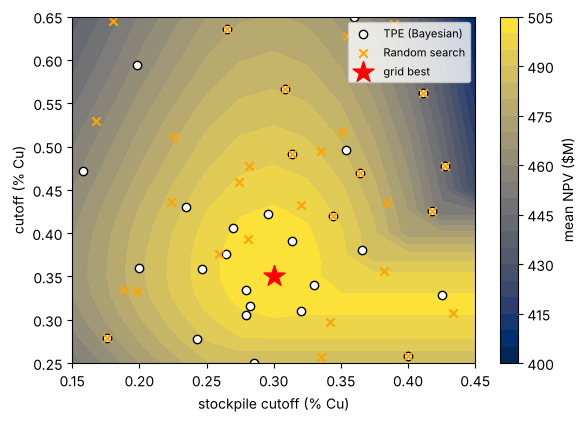

In [15]:
CUTS = np.round(np.arange(0.25, 0.651, 0.025), 3)        # 17 cutoffs
STOCKS = np.round(np.arange(0.15, 0.451, 0.025), 3)      # 13 stockpile cutoffs

t0 = time.perf_counter()
with ProcessPoolExecutor() as pool:
    grid = np.array(list(pool.map(sgs_tools.policy_grid, train, TRAIN, [CUTS] * 30, [STOCKS] * 30)))
print(f"{grid.size} mine simulations in {time.perf_counter() - t0:.1f} s")

mean_grid = grid.mean(axis=0)                            # mean NPV of every policy
i, j = np.unravel_index(mean_grid.argmax(), mean_grid.shape)
grid_best = mean_grid.max()
print(f"Grid best: cutoff {CUTS[i]}, stockpile {STOCKS[j]} -> {grid_best:.1f} $M   (BO found {summary['BO_train_NPV']} with 30 trials)")
summary["grid_policy"] = [float(CUTS[i]), float(STOCKS[j])]
summary["grid_train_NPV"] = round(float(grid_best), 1)

plt.figure(figsize=(6.5, 4.5))
plt.contourf(STOCKS, CUTS, mean_grid, levels=20, cmap="cividis")
plt.colorbar(label="mean NPV ($M)")
for name, marker in [("TPE (Bayesian)", "o"), ("Random search", "x")]:
    tr = studies[name].trials
    plt.scatter([t.params["stockpile_cutoff"] for t in tr], [t.params["cutoff"] for t in tr],
                marker=marker, c="white" if marker == "o" else "orange", edgecolors="black", label=name)
plt.scatter([STOCKS[j]], [CUTS[i]], marker="*", s=250, c="red", label="grid best")
plt.xlabel("stockpile cutoff (% Cu)"); plt.ylabel("cutoff (% Cu)"); plt.legend(fontsize=8); plt.show()

---
## Task D3 · Check on deposits the optimizer never saw
Evaluate your BO policy and the first guess on the 100 test realizations.

In [16]:
bo_test = npvs(best["cutoff"], best["stockpile_cutoff"], test, TEST)
guess_test = npvs(0.42, 0.32, test, TEST)
print(f"Test mean NPV:  BO policy {bo_test.mean():.1f} $M   first guess {guess_test.mean():.1f} $M"
      f"   (gain {bo_test.mean() - guess_test.mean():+.1f} $M)")
print(f"Training said {summary['BO_train_NPV']} $M: the difference is the optimism of tuning on the same data")
summary["BO_test_NPV"] = round(float(bo_test.mean()), 1)

Test mean NPV:  BO policy 477.4 $M   first guess 475.0 $M   (gain +2.4 $M)
Training said 502.6 $M: the difference is the optimism of tuning on the same data


# Part E · Regret (10 min)
Regret = what you lost compared with the best you could have done. Three versions.

---
## Task E1 · Search regret: Bayesian optimization vs random search
Like a bandit: every trial on a worse policy costs (grid best − that trial's NPV). Cumulative regret adds them up; simple regret is grid best − best found so far.

TPE (Bayesian)  cumulative regret after 30 trials   566.1 $M,  simple regret   1.4 $M
Random search   cumulative regret after 30 trials   702.3 $M,  simple regret   1.6 $M


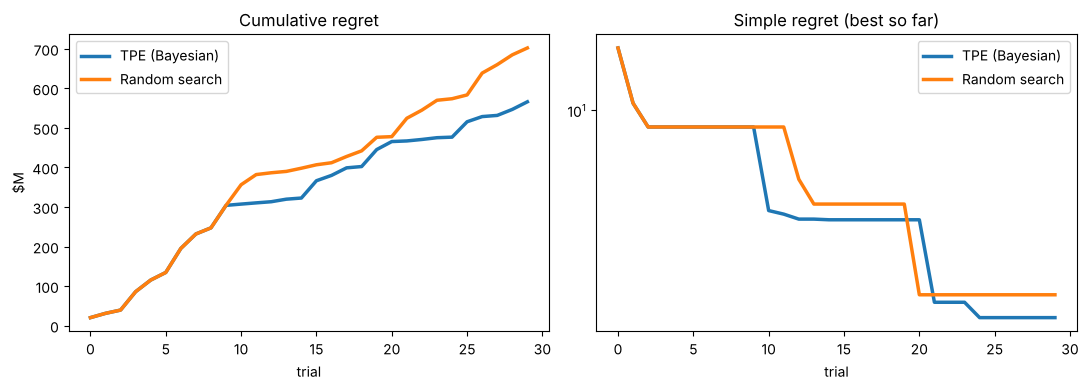

In [17]:
plt.figure(figsize=(11, 4))
for k, name in enumerate(studies):
    values = np.array([t.value for t in studies[name].trials])
    regret = grid_best - values
    plt.subplot(1, 2, 1); plt.plot(np.cumsum(regret), lw=2.5, label=name)
    plt.subplot(1, 2, 2); plt.plot(grid_best - np.maximum.accumulate(values), lw=2.5, label=name)
    print(f"{name:15s} cumulative regret after 30 trials {regret.sum():7.1f} $M,"
          f"  simple regret {grid_best - values.max():5.1f} $M")
    summary[f"cum_regret_{'TPE' if k == 0 else 'random'}"] = round(float(regret.sum()), 1)
plt.subplot(1, 2, 1); plt.title("Cumulative regret"); plt.xlabel("trial"); plt.ylabel("$M"); plt.legend()
plt.subplot(1, 2, 2); plt.title("Simple regret (best so far)"); plt.xlabel("trial"); plt.yscale("symlog"); plt.legend()
plt.tight_layout(); plt.show()

---
## Task E2 · Decision regret: planning on the average model
A common shortcut: optimize the policy on ONE smooth model (the E-type) instead of on the realizations. What does it cost?

In [18]:
etype_grid = sgs_tools.policy_grid(etype, 0, CUTS, STOCKS)
a, b = np.unravel_index(etype_grid.argmax(), etype_grid.shape)
etype_test = npvs(CUTS[a], STOCKS[b], test, TEST)
print(f"E-type plan: cutoff {CUTS[a]}, stockpile {STOCKS[b]}.  The E-type model says NPV = {etype_grid.max():.1f} $M")
print(f"On the 100 test realizations it makes {etype_test.mean():.1f} $M  (valuation error {etype_grid.max() - etype_test.mean():+.1f} $M)")
print(f"BO policy (optimized on realizations) makes {bo_test.mean():.1f} $M  ->  regret of the E-type plan {bo_test.mean() - etype_test.mean():+.1f} $M")
print("(a negative regret means the E-type plan happened to do slightly better on the test deposits)")
summary["Etype_valuation_error"] = round(float(etype_grid.max() - etype_test.mean()), 1)
summary["Etype_regret"] = round(float(bo_test.mean() - etype_test.mean()), 1)

E-type plan: cutoff 0.375, stockpile 0.3.  The E-type model says NPV = 420.1 $M
On the 100 test realizations it makes 478.8 $M  (valuation error -58.6 $M)
BO policy (optimized on realizations) makes 477.4 $M  ->  regret of the E-type plan -1.4 $M
(a negative regret means the E-type plan happened to do slightly better on the test deposits)


---
## Task E3 · Value of perfect information
If we knew which realization is the true deposit, we would pick its best policy. Regret per realization = its best NPV − our policy's NPV. Computing every realization's best policy = 100 independent grid searches: in parallel.

In [19]:
CUTS_C = np.round(np.arange(0.25, 0.651, 0.05), 2)       # a coarser grid: 9 x 7 = 63 policies
STOCKS_C = np.round(np.arange(0.15, 0.451, 0.05), 2)
t0 = time.perf_counter()
with ProcessPoolExecutor() as pool:
    hind = np.array(list(pool.map(sgs_tools.policy_grid, test, TEST, [CUTS_C] * 100, [STOCKS_C] * 100)))
best_in_hindsight = np.maximum(hind.reshape(100, -1).max(axis=1), bo_test)
regret = best_in_hindsight - bo_test
print(f"100 grid searches in {time.perf_counter() - t0:.1f} s")
print(f"Regret of the BO policy: mean {regret.mean():.1f} $M (the value of perfect information),  P90 {np.percentile(regret, 90):.1f} $M,  max {regret.max():.1f} $M")
summary["value_of_perfect_info"] = round(float(regret.mean()), 1)

100 grid searches in 14.1 s
Regret of the BO policy: mean 2.7 $M (the value of perfect information),  P90 5.9 $M,  max 12.2 $M


# Part F · Risk (10 min)

---
## Task F1 · The NPV distribution of your plan
One policy, 100 equally likely deposits. P10 = 10 % of deposits do worse. CVaR10 = average of the worst 10 %.

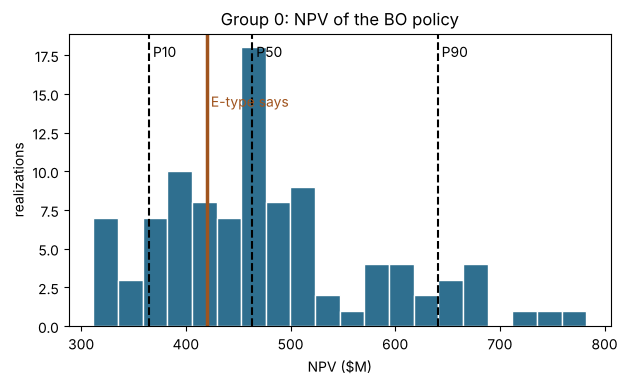

P10 364.9   P50 463.5   P90 640.6   CVaR10 329.8  $M


In [20]:
p10, p50, p90 = np.percentile(bo_test, [10, 50, 90])
cvar10 = np.sort(bo_test)[:10].mean()
plt.figure(figsize=(7, 3.8))
plt.hist(bo_test, bins=20, color="#2F6F8F", edgecolor="white")
for v, lab in [(p10, "P10"), (p50, "P50"), (p90, "P90")]:
    plt.axvline(v, color="black", ls="--"); plt.text(v, plt.ylim()[1] * 0.92, " " + lab)
plt.axvline(etype_grid.max(), color="#A0541E", lw=2.5); plt.text(etype_grid.max(), plt.ylim()[1] * 0.75, " E-type says", color="#A0541E")
plt.xlabel("NPV ($M)"); plt.ylabel("realizations"); plt.title(f"Group {GROUP}: NPV of the BO policy"); plt.show()
print(f"P10 {p10:.1f}   P50 {p50:.1f}   P90 {p90:.1f}   CVaR10 {cvar10:.1f}  $M")
summary["NPV_P10_P50_P90"] = [round(float(x), 1) for x in (p10, p50, p90)]
summary["NPV_CVaR10"] = round(float(cvar10), 1)

---
## Task F2 · A risk-aware objective
Optimize the P10 (the bad case) instead of the mean, then compare both policies on the test realizations.

In [21]:
def objective_p10(trial):
    cutoff = trial.suggest_float("cutoff", 0.25, 0.65)
    stockpile_cutoff = trial.suggest_float("stockpile_cutoff", 0.15, 0.45)
    return np.percentile(npvs(cutoff, stockpile_cutoff, train, TRAIN), 10)

study_p10 = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=GROUP))
study_p10.optimize(objective_p10, n_trials=30)
rp = study_p10.best_params
risk_test = npvs(rp["cutoff"], rp["stockpile_cutoff"], test, TEST)
print(f"{'Objective':10s} {'policy':>14s} {'test mean':>10s} {'test P10':>9s}")
print(f"{'mean':10s} {best['cutoff']:.3f} / {best['stockpile_cutoff']:.3f} {bo_test.mean():10.1f} {np.percentile(bo_test, 10):9.1f}")
print(f"{'P10':10s} {rp['cutoff']:.3f} / {rp['stockpile_cutoff']:.3f} {risk_test.mean():10.1f} {np.percentile(risk_test, 10):9.1f}")
summary["P10_policy"] = [round(rp["cutoff"], 3), round(rp["stockpile_cutoff"], 3)]

Objective          policy  test mean  test P10
mean       0.391 / 0.314      477.4     364.9
P10        0.310 / 0.320      476.2     368.7


# Part G · Extension: choose the policy with a bandit

---
## Task G1 · UCB over three cutoffs
Three levers = three cutoffs: 0.25 %, your BO cutoff, 0.60 % (all with your BO stockpile cutoff). Each pull simulates one random deposit from the test pool and returns its NPV. The bandit does not know the true means; we do (100 test realizations), so we can measure its regret.

Arms (cutoff): [0.25, 0.39, 0.6]   true mean NPV: [461.7 477.4 455.1]   gaps: [15.8  0.  22.3]


UCB             regret after 300 pulls    2189 $M   pulls of the best arm 183 / 300


epsilon-greedy  regret after 300 pulls    2489 $M   pulls of the best arm 168 / 300


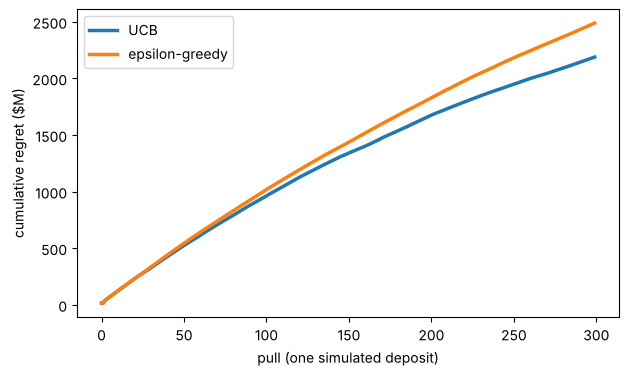

In [22]:
arms = [0.25, round(best["cutoff"], 2), 0.60]
table = np.array([npvs(c, best["stockpile_cutoff"], test, TEST) for c in arms])   # NPV of each arm on each test deposit
true_mean = table.mean(axis=1)
gap = true_mean.max() - true_mean
print("Arms (cutoff):", arms, "  true mean NPV:", np.round(true_mean, 1), "  gaps:", np.round(gap, 1))

def run_bandit(method, pulls=300, c=120, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    N, Q = np.zeros(3), np.zeros(3)
    regret = []
    for t in range(1, pulls + 1):
        if t <= 3:
            a = t - 1                                                   # try each arm once
        elif method == "UCB":
            a = np.argmax(Q + c * np.sqrt(np.log(t) / N))
        else:
            a = rng.integers(3) if rng.random() < eps else np.argmax(Q)
        r = table[a, rng.integers(table.shape[1])]                      # one new deposit
        N[a] += 1
        Q[a] += (r - Q[a]) / N[a]                                       # running average
        regret.append(gap[a])
    return np.cumsum(regret), N

plt.figure(figsize=(7, 4))
for method in ["UCB", "epsilon-greedy"]:
    runs = [run_bandit(method, seed=s) for s in range(200)]
    curve = np.mean([r[0] for r in runs], axis=0)
    pulls_best = np.mean([r[1][np.argmax(true_mean)] for r in runs])
    plt.plot(curve, lw=2.5, label=method)
    print(f"{method:15s} regret after 300 pulls {curve[-1]:7.0f} $M   pulls of the best arm {pulls_best:.0f} / 300")
plt.xlabel("pull (one simulated deposit)"); plt.ylabel("cumulative regret ($M)"); plt.legend(); plt.show()

# Part H · Extension: the repair-crew challenge (lecture MDP)
Two shovels, two trucks, one crusher, one repair crew on day shifts. Build the MDP, solve it with value iteration, then write **your own crew rule** and measure its regret.

---
## Task H1 · Build the MDP

In [23]:
types = {
    #          output kt/shift   wear per running shift    crew: maintenance   crew: repair
    "Shovel":  dict(good=7,  worn=5,  p_wear=0.10, p_break=0.20, m_cost=5,  r_cost=20, p_fixed=0.50),
    "Truck":   dict(good=6.5, worn=5, p_wear=0.15, p_break=0.25, m_cost=8,  r_cost=15, p_fixed=0.70),
    "Crusher": dict(good=16, worn=12, p_wear=0.05, p_break=0.10, m_cost=15, r_cost=40, p_fixed=0.25),
}
machines = ["Shovel 1", "Shovel 2", "Truck 1", "Truck 2", "Crusher"]
kind = {m: m.split()[0] for m in machines}      # "Shovel 1" -> "Shovel"
MARGIN = 8                                       # $ per tonne: 1 kt moved = $8k
gamma_f = 0.99                                   # a shift is short: look about 100 shifts ahead

def line_output(conditions, crew_on):
    """kt moved this shift: loading, hauling and crushing capacity of the machines that run; the smallest wins."""
    capacity = {"Shovel": 0, "Truck": 0, "Crusher": 0}
    for m, c in zip(machines, conditions):
        if c != "Broken" and m != crew_on:                       # a machine with the crew on it is down
            capacity[kind[m]] += types[kind[m]]["good" if c == "Good" else "worn"]
    return min(capacity.values())

def next_condition(m, c, crew_on, line_runs):
    spec = types[kind[m]]
    if m == crew_on:
        return {"Good": spec["p_fixed"], "Broken": 1 - spec["p_fixed"]} if c == "Broken" else {"Good": 0.9, "Worn": 0.1}
    if c == "Broken" or not line_runs:                           # waiting for the crew, or line stopped: no change
        return {c: 1.0}
    if c == "Good":
        return {"Good": 1 - spec["p_wear"], "Worn": spec["p_wear"]}
    return {"Worn": 1 - spec["p_break"], "Broken": spec["p_break"]}

print("Good line:", line_output(["Good"] * 5, None), "kt  -> $", MARGIN * line_output(["Good"] * 5, None), "k per shift")
print("Truck 2 broken:", line_output(["Good", "Good", "Good", "Broken", "Good"], None), "kt")

Good line: 13.0 kt  -> $ 104.0 k per shift
Truck 2 broken: 6.5 kt


In [24]:
import itertools

# Same format as the shovel:  (state, action) -> (reward, {next state: probability})
# state  = (Shovel 1, Shovel 2, Truck 1, Truck 2, Crusher, "day" or "night")
# action = the machine the crew works on this shift, or None. The crew only works day shifts.
fleet_model, fleet_actions = {}, {}
for conditions in itertools.product(["Good", "Worn", "Broken"], repeat=5):
    for shift in ["day", "night"]:
        state = (*conditions, shift)
        options = [None]
        if shift == "day":
            options += [m for m, c in zip(machines, conditions) if c != "Good"]   # repair Broken or maintain Worn
        fleet_actions[state] = options

        for crew_on in options:
            output = line_output(conditions, crew_on)
            reward = MARGIN * output
            if crew_on is not None:
                c = conditions[machines.index(crew_on)]
                spec = types[kind[crew_on]]
                reward -= spec["r_cost"] if c == "Broken" else spec["m_cost"]

            each = [next_condition(m, c, crew_on, output > 0) for m, c in zip(machines, conditions)]
            next_states = {}
            for combo in itertools.product(*[d.items() for d in each]):          # machines change independently
                p = np.prod([prob for _, prob in combo])
                nxt = (*[cond for cond, _ in combo], "night" if shift == "day" else "day")
                next_states[nxt] = next_states.get(nxt, 0) + p
            fleet_model[(state, crew_on)] = (reward, next_states)

print("states:", len(fleet_actions), "  state-action pairs:", len(fleet_model))

states: 486   state-action pairs: 1296


---
## Task H2 · Solve it with value iteration

In [25]:
def fleet_value(state, action, V):
    reward, next_states = fleet_model[(state, action)]
    return reward + gamma_f * sum(p * V[s] for s, p in next_states.items())

V = {s: 0.0 for s in fleet_actions}
while True:
    new_V = {s: max(fleet_value(s, a, V) for a in fleet_actions[s]) for s in V}
    change = max(abs(new_V[s] - V[s]) for s in V)
    V = new_V
    if change < 0.01:
        break
best_policy = {s: max(fleet_actions[s], key=lambda a: fleet_value(s, a, V)) for s in V}

def expected_profit(policy, shifts=730):
    prob = {s: 0.0 for s in fleet_actions}
    prob[("Good",) * 5 + ("day",)] = 1.0
    total = 0.0
    for _ in range(shifts):
        new_prob = {s: 0.0 for s in fleet_actions}
        for s, p in prob.items():
            if p > 0:
                reward, next_states = fleet_model[(s, policy(s))]
                total += p * reward
                for ns, q in next_states.items():
                    new_prob[ns] += p * q
        prob = new_prob
    return total / shifts

optimal_profit = expected_profit(lambda s: best_policy[s])
print(f"Optimal crew policy: {optimal_profit:.2f} $k per shift")

Optimal crew policy: 56.55 $k per shift


---
## Task H3 · Your rule vs the optimum
Edit `my_rule`. A state looks like `('Good', 'Worn', 'Good', 'Broken', 'Good', 'day')` (Shovel 1, Shovel 2, Truck 1, Truck 2, Crusher, shift). Return the machine the crew works on, or `None`. At night, or on a Good machine, the only allowed answer is `None`.

In [26]:
def my_rule(s):
    if s[5] == "night":
        return None
    conditions = dict(zip(machines, s[:5]))
    for m in ["Crusher", "Truck 1", "Truck 2", "Shovel 1", "Shovel 2"]:     # repair first, crusher first
        if conditions[m] == "Broken":
            return m
    for m in ["Crusher", "Truck 1", "Truck 2", "Shovel 1", "Shovel 2"]:     # then maintain
        if conditions[m] == "Worn":
            return m
    return None

mine = expected_profit(my_rule)
summary["crew_rule_regret_per_year_M"] = round((optimal_profit - mine) * 730 / 1000, 2)
print(f"Your rule: {mine:.2f} $k/shift.  Regret: {optimal_profit - mine:.2f} $k per shift = "
      f"{summary['crew_rule_regret_per_year_M']} $M per year")

Your rule: 50.49 $k/shift.  Regret: 6.05 $k per shift = 4.42 $M per year


# Report · Your group summary
Copy this into the class table. Then discuss the questions on the last slide.

In [27]:
for key, value in summary.items():
    print(f"{key:28s} {value}")

group                        0
holes_mean_grade             0.459
speedup                      1.71
ore_P10_P50_P90_Mt           [11.1, 13.4, 17.9]
realizations_needed          49
first_guess_mean_NPV         500.1
BO_policy                    [0.391, 0.314]
BO_train_NPV                 502.6
grid_policy                  [0.35, 0.3]
grid_train_NPV               504.0
BO_test_NPV                  477.4
cum_regret_TPE               566.1
cum_regret_random            702.3
Etype_valuation_error        -58.6
Etype_regret                 -1.4
value_of_perfect_info        2.7
NPV_P10_P50_P90              [364.9, 463.5, 640.6]
NPV_CVaR10                   329.8
P10_policy                   [0.31, 0.32]
crew_rule_regret_per_year_M  4.42
